# Simulation: testing the learned laws as a forward model

Each learned law from `training.ipynb` is used to simulate the flock over the full 140 s (18980–19120 s):

- the leader (bird A) replays its measured flight (cubic interpolation, as in the original simulation notebook);
- the 9 followers start from their measured position and velocity at 18980 s and then move **only** according to
  the learned law (self-propulsion + pairwise forces), integrated with RK45 (maximum step 0.01 s);
- the first 20 s are the training window; 20–140 s were never seen in training.

**Metrics** (every 0.2 s, averaged over 20–140 s):
- *follower position error*: mean distance between simulated and measured followers;
- *cohesion*: mean distance of the birds from the flock centre (measured: 6.3 m);
- *polarization*: length of the mean heading vector, 1 = all fly the same way (measured: 0.98);
- *top speed* of any follower (a simulation "blows up" above 50 m/s; real pigeons fly about 12 m/s).

A *rigid formation*, where every follower keeps its starting offset from the leader, is the reference (14 m).

By default the notebook simulates the shipped coefficients of all 40 runs (about 5-10 minutes on a laptop CPU).

In [1]:
# Standard library
import time
from pathlib import Path

# Third-party
# torch is imported BEFORE pandas on purpose: on Windows, pandas loads the optional package pyarrow,
# whose own older copy of a system library (msvcp140.dll) can otherwise stop torch from loading.
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

## Settings

In [2]:
RESULTS_DIR = Path("results")      # learned coefficients to simulate; use Path("outputs") for your own runs
VARIANTS_TO_SIMULATE = ['full', 'hic', 'aw2', 'pull_tail_v0']
SEEDS = range(10)

DATA_CSV = Path("data/pigeon_flock_18980_to_19120.csv")
OUTPUT_DIR = Path("outputs")
FIGURES_DIR = Path("figures")
TRAIN_END = 20.0                   # s after 18980 s where the training data ends
MAX_STEP = 0.01                    # s: largest solver step (as in the original)
LEADER = 0                         # column of bird A, the leader
BLOW_UP_SPEED = 50.0               # m/s: a follower faster than this means the simulation blew up
GOOD_ERROR, BREAK_AWAY_ERROR = 150.0, 400.0   # m: follows the leader / has broken away
LABELS = {'full': 'Baseline', 'hic': 'Hard IC', 'aw2': 'Adaptive weights', 'pull_tail_v0': 'Constrained law'}
# Constraints that training applied to the law, which the simulation must apply too
LAW_OPTIONS = {'pull_tail_v0': {'distance_cap': 59.0, 'max_acceleration': 10.0}}
PHYSICS_PARAM_NAMES = ['lambda1', 'lambda2', 'lambda3', 'lambda4', 'power1', 'power2', 'power3',
                       'lambda1_v', 'lambda2_v', 'lambda3_v', 'lambda4_v', 'power1_v', 'power2_v', 'power3_v',
                       'a1_dist', 'a2_dist', 'a3_dist', 'a4_dist', 'a5_dist', 'a1_v', 'a2_v', 'a3_v', 'a4_v', 'a5_v',
                       'tau']

## Data

The data are loaded exactly as in training (32-bit floats, one common centre), then turned into 64-bit NumPy
arrays for the ODE solver.

In [3]:
AGENT_LABELS = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N']   # labels that may appear


def load_flock_data(table):
    """Turn trajectory rows into PyTorch tensors (same steps as the original notebook).

    Input:  table = DataFrame with columns t(s), X(m)_A, Y(m)_A, dX/dt(m/s)_A, dY/dt(m/s)_A, ... (one row per frame)
    Output: tensors = dict with
                't'              time since the first frame, shape [frames, 1]
                'X', 'Y'         positions, shape [frames, birds], centred on ONE common mean
                'dX/dt', 'dY/dt' measured velocities, shape [frames, birds]
            v0_mean = mean speed over all birds and frames (the cruising speed of the physics law)
            agents  = bird labels found in the file (the first one, A, is the leader)
    """
    agents = [a for a in AGENT_LABELS if f'X(m)_{a}' in table.columns]

    def columns(prefix):
        # np.stack(..., axis=1) puts the birds side by side: array of shape [frames, birds]
        return np.stack([table[f'{prefix}_{a}'].values for a in agents], axis=1)

    def to_tensor(array):
        return torch.tensor(array, dtype=torch.float32)   # 32-bit floats, as in the original

    t = to_tensor(table['t(s)'].values)
    X, Y = to_tensor(columns('X(m)')), to_tensor(columns('Y(m)'))
    dX, dY = to_tensor(columns('dX/dt(m/s)')), to_tensor(columns('dY/dt(m/s)'))
    t = (t - t[0]).reshape(len(t), 1)        # start the clock at 0; a column vector is the network input
    # One common mean for all birds keeps the distances between birds unchanged
    X, Y = X - torch.mean(X), Y - torch.mean(Y)
    v0_mean = torch.mean(torch.sqrt(dX**2 + dY**2))
    return {'t': t, 'X': X, 'Y': Y, 'dX/dt': dX, 'dY/dt': dY}, v0_mean, agents


def load_window(path):
    """The whole 140 s window as NumPy arrays: 't' (s since 18980 s), 'X', 'Y', 'VX', 'VY' [frames, birds]."""
    tensors, _, agents = load_flock_data(pd.read_csv(path))
    as_array = lambda key: tensors[key].numpy().astype(np.float64)   # .numpy(): tensor -> NumPy array
    return {'t': as_array('t')[:, 0], 'X': as_array('X'), 'Y': as_array('Y'),
            'VX': as_array('dX/dt'), 'VY': as_array('dY/dt'), 'agents': agents}


data = load_window(DATA_CSV)
print(f"{len(data['t'])} frames, birds {data['agents']}")

701 frames, birds ['A', 'B', 'C', 'D', 'G', 'H', 'I', 'J', 'L', 'M']


## The learned law and the simulator

`interaction_acceleration` is the same force law as in training, written with NumPy for one moment in time.
`simulate` integrates the followers' equations of motion: d(position)/dt = velocity, d(velocity)/dt = law.

In [4]:
def sigmoid(x):
    """Squash any number into (0, 1); used for the field-of-view weights."""
    return 1 / (1 + np.exp(-x))


def interaction_acceleration(pos, vel, p, distance_cap=None, max_acceleration=None):
    """Sum of the pairwise forces on every bird (the training formula).

    Inputs: pos, vel [birds, 2]; p = dict of learned coefficients; the optional constraints.
    Output: [birds, 2] total interaction force on each bird (mass 1, so force = acceleration).
    """
    num_agents = len(pos)
    # Broadcasting: pos[:, None] - pos[None, :] gives every pair [receiver i, sender j, xy]
    rel_pos = pos[:, None, :] - pos[None, :, :]
    rel_vel = vel[:, None, :] - vel[None, :, :]
    dist = np.linalg.norm(rel_pos, axis=2)
    speed_rel = np.linalg.norm(rel_vel, axis=2)
    dist_law = dist if distance_cap is None else np.minimum(dist, distance_cap)
    heading_x, heading_y = vel[:, None, 0], vel[:, None, 1]
    angle = np.arctan2(heading_y * (-rel_pos[..., 0]) - heading_x * (-rel_pos[..., 1]),
                       heading_x * (-rel_pos[..., 0]) + heading_y * (-rel_pos[..., 1]))

    def angular_weight(suffix):
        return sigmoid(sum(p[f'a{k}_{suffix}'] * np.cos(k * angle) for k in range(1, 5)) + p[f'a5_{suffix}'])

    def radial_law(suffix):
        return sum(p[f'lambda{k}{suffix}'] * dist_law ** p[f'power{k}{suffix}'] for k in range(1, 4)) + p[f'lambda4{suffix}']

    # errstate silences the 0/0 warnings for a bird paired with itself, which is set to zero below
    with np.errstate(divide='ignore', invalid='ignore'):
        distance_force = (rel_pos / dist[..., None]) * (radial_law('') * angular_weight('dist'))[..., None]
        alignment_force = (rel_vel / speed_rel[..., None]) * (radial_law('_v') * angular_weight('v'))[..., None]
    pair_force = distance_force + alignment_force
    pair_force[np.arange(num_agents), np.arange(num_agents)] = 0.0
    total = pair_force.sum(axis=1)
    if max_acceleration is not None:     # smooth cap: length L -> limit * tanh(L / limit), direction kept
        length = np.sqrt(np.sum(total ** 2, axis=1, keepdims=True) + 1e-12)
        total = total * max_acceleration * np.tanh(length / max_acceleration) / length
    return total


def self_propulsion(vel, v0, tau):
    """Pull each bird's speed toward v0 with relaxation time |tau|."""
    speed = np.linalg.norm(vel, axis=1, keepdims=True)
    return (1 / abs(tau)) * vel * (v0 / speed - 1)


def simulate(data, params, v0, options):
    """Integrate the 9 followers from the first frame; the leader replays its measured track.

    Output: dict 'X', 'Y', 'VX', 'VY' [frames, birds] on the data's time grid (NaN after a solver failure),
            plus 'solver' (success flag and run time).
    """
    columns = np.column_stack([data[key][:, LEADER] for key in ('X', 'Y', 'VX', 'VY')])
    leader = interp1d(data['t'], columns, kind='cubic', axis=0, fill_value='extrapolate')
    # One cruising speed per follower as a column [followers, 1], or one number for all
    v0_followers = np.asarray(v0, dtype=float)[1:, None] if np.ndim(v0) else v0

    def rhs(t, state):
        # state = followers' [x, y, vx, vy], flattened; returns its time derivative
        followers = state.reshape(-1, 4)
        leader_now = leader(t)
        pos = np.vstack([leader_now[:2], followers[:, :2]])
        vel = np.vstack([leader_now[2:], followers[:, 2:]])
        accel = (interaction_acceleration(pos, vel, params, options.get('distance_cap'), options.get('max_acceleration'))[1:]
                 + self_propulsion(vel[1:], v0_followers, params['tau']))
        return np.hstack([followers[:, 2:], accel]).ravel()

    initial = np.column_stack([data[key][0, 1:] for key in ('X', 'Y', 'VX', 'VY')]).ravel()
    start = time.perf_counter()
    solution = solve_ivp(rhs, (data['t'][0], data['t'][-1]), initial, method='RK45', max_step=MAX_STEP,
                         t_eval=data['t'])
    num_frames = len(data['t'])
    states = np.full((num_frames, solution.y.shape[0]), np.nan)   # NaN marks frames never reached
    states[:solution.y.shape[1]] = solution.y.T
    states = states.reshape(num_frames, -1, 4)
    sim = {key: np.column_stack([data[key][:, LEADER], states[:, :, column]])
           for column, key in enumerate(('X', 'Y', 'VX', 'VY'))}
    sim['solver'] = {'success': bool(solution.success), 'runtime_s': time.perf_counter() - start}
    return sim

## Metrics

In [5]:
def rigid_formation(data):
    """Reference: every follower keeps its starting offset from the leader and copies its velocity."""
    ref = {}
    for key, vel_key in (('X', 'VX'), ('Y', 'VY')):
        offset = data[key][0] - data[key][0, LEADER]
        ref[key] = data[key][:, [LEADER]] + offset[None, :]      # [:, [0]] keeps a column shape
        ref[vel_key] = np.repeat(data[vel_key][:, [LEADER]], data[vel_key].shape[1], axis=1)
    return ref


def flock_cohesion(X, Y):
    """Mean distance of the birds from the flock centre, per frame."""
    return np.mean(np.hypot(X - X.mean(axis=1, keepdims=True), Y - Y.mean(axis=1, keepdims=True)), axis=1)


def polarization(VX, VY):
    """Length of the mean heading vector per frame: 1 = all birds fly the same direction."""
    speed = np.hypot(VX, VY)
    return np.hypot(np.mean(VX / speed, axis=1), np.mean(VY / speed, axis=1))


def follower_position_error(model, data):
    """Mean distance (m) between modelled and measured followers, per frame."""
    return np.mean(np.hypot(model['X'][:, 1:] - data['X'][:, 1:], model['Y'][:, 1:] - data['Y'][:, 1:]), axis=1)


def run_summary(sim, data):
    """Means over the unseen 20-140 s and the top follower speed over the whole simulation."""
    unseen = data['t'] > TRAIN_END + 1e-9
    # nanmean skips the frames after a solver failure (NaN)
    mean = lambda values: float(np.nanmean(values[unseen]))
    return {'solver_ok': sim['solver']['success'],
            'pos_err_20_140s': mean(follower_position_error(sim, data)),
            'rigid_err_20_140s': mean(follower_position_error(rigid_formation(data), data)),
            'cohesion_sim': mean(flock_cohesion(sim['X'], sim['Y'])),
            'cohesion_data': mean(flock_cohesion(data['X'], data['Y'])),
            'polar_sim': mean(polarization(sim['VX'], sim['VY'])),
            'polar_data': mean(polarization(data['VX'], data['VY'])),
            # nanmax ignores frames after a solver failure
            'max_speed_sim': float(np.nanmax(np.hypot(sim['VX'][:, 1:], sim['VY'][:, 1:]))),
            'runtime_s': round(sim['solver']['runtime_s'], 1)}

## Simulate every run

Takes about 5-20 s per run. The two runs shown in Figure 2 are kept in memory.

In [6]:
def learned_law(row):
    """(coefficients dict, cruising speed, law options) of one row of learned_coefficients.csv."""
    params = {name: float(row[name]) for name in PHYSICS_PARAM_NAMES}
    per_bird = [f'v0_{agent}' for agent in data['agents']]
    v0 = row[per_bird].astype(float).tolist() if row[per_bird].notna().all() else float(row['v0'])
    return params, v0, LAW_OPTIONS.get(row['variant'], {})


# float_precision="round_trip": read the coefficients back exactly as they were written
coefficients = pd.read_csv(RESULTS_DIR / "learned_coefficients.csv", float_precision="round_trip")
SHOWCASE = [('full', 3), ('pull_tail_v0', 3)]     # the two runs of Figure 2
showcase_sims, summaries = {}, []
for _, row in coefficients.iterrows():
    if row.variant not in VARIANTS_TO_SIMULATE or row.seed not in SEEDS:
        continue
    params, v0, options = learned_law(row)
    if not all(np.isfinite(list(params.values()))):
        print(f"skipped {row.variant} seed {row.seed}: NaN coefficients")
        continue
    sim = simulate(data, params, v0, options)
    summary = {'variant': row.variant, 'seed': row.seed, **run_summary(sim, data)}
    summaries.append(summary)
    if (row.variant, row.seed) in SHOWCASE:
        showcase_sims[(row.variant, row.seed)] = sim
    print(f"{row.variant:>13} seed {row.seed}: error {summary['pos_err_20_140s']:7.1f} m, "
          f"top speed {summary['max_speed_sim']:6.1f} m/s ({summary['runtime_s']} s)")

runs = pd.DataFrame(summaries)
OUTPUT_DIR.mkdir(exist_ok=True)
runs.to_csv(OUTPUT_DIR / "simulation_metrics.csv", index=False)

         full seed 0: error   105.1 m, top speed   13.6 m/s (18.4 s)


         full seed 1: error    79.5 m, top speed   19.6 m/s (26.3 s)


         full seed 2: error    95.0 m, top speed   14.8 m/s (27.0 s)


         full seed 3: error   200.5 m, top speed  115.2 m/s (25.5 s)


         full seed 4: error   263.1 m, top speed  902.5 m/s (26.5 s)


         full seed 5: error    65.5 m, top speed   30.0 m/s (26.4 s)


... (30 outputs left out)

 pull_tail_v0 seed 6: error    82.3 m, top speed   18.2 m/s (24.1 s)


 pull_tail_v0 seed 7: error   193.3 m, top speed   20.0 m/s (20.4 s)


 pull_tail_v0 seed 8: error   162.5 m, top speed   34.0 m/s (20.4 s)


 pull_tail_v0 seed 9: error    87.1 m, top speed   17.4 m/s (22.6 s)


## Summary table

All 10 runs per method, simulation metrics over 20–140 s. *p*: Mann–Whitney test of the position errors against
the baseline (are this method's errors typically larger or smaller?). Runs with error > 400 m broke away from the
leader.

In [7]:
def summary_table(runs, coefficients):
    """One column per variant: training loss and simulation metrics over 20-140 s."""
    merged = runs.merge(coefficients[['variant', 'seed', 'loss_total']], on=['variant', 'seed'])
    baseline_errors = merged[merged.variant == 'full'].pos_err_20_140s
    table = {}
    for variant in VARIANTS_TO_SIMULATE:
        group = merged[merged.variant == variant]
        errors = group.pos_err_20_140s
        table[LABELS[variant]] = {
            'median final training loss': round(group.loss_total.median(), 2),
            'position error median / best (m)': f"{errors.median():.0f} / {errors.min():.0f}",
            'p against baseline': '-' if variant == 'full' else round(mannwhitneyu(errors, baseline_errors).pvalue, 3),
            'runs <150 / 150-400 / >400 m': f"{(errors < GOOD_ERROR).sum()} / "
                                            f"{((errors >= GOOD_ERROR) & (errors <= BREAK_AWAY_ERROR)).sum()} / "
                                            f"{(errors > BREAK_AWAY_ERROR).sum()}",
            'blow-ups (> 50 m/s)': int((group.max_speed_sim > BLOW_UP_SPEED).sum()),
            'median cohesion (m)': round(group.cohesion_sim.median(), 1),
            'median polarization': round(group.polar_sim.median(), 3),
        }
    return pd.DataFrame(table)


reference = runs.iloc[0]    # measured and rigid-formation values are the same for every run
print(f"References over 20-140 s: rigid formation {reference.rigid_err_20_140s:.1f} m, measured cohesion "
      f"{reference.cohesion_data:.1f} m, measured polarization {reference.polar_data:.3f}")
summary_table(runs, coefficients)

References over 20-140 s: rigid formation 14.0 m, measured cohesion 6.3 m, measured polarization 0.982


,Baseline,Hard IC,Adaptive weights,Constrained law
median final training loss,8.82,5.34,73.07,8.48
position error median / best (m),153 / 65,660 / 78,657 / 169,88 / 80
p against baseline,-,0.104,0.006,0.623
runs <150 / 150-400 / >400 m,5 / 2 / 3,3 / 2 / 5,0 / 2 / 8,6 / 3 / 1
blow-ups (> 50 m/s),2,8,0,0
median cohesion (m),36.7,123.1,118.5,20.8
median polarization,0.889,0.881,0.891,0.929


## Flight paths of two learned laws

Left: the baseline law from seed 3. Right: the constrained law from the same seed.

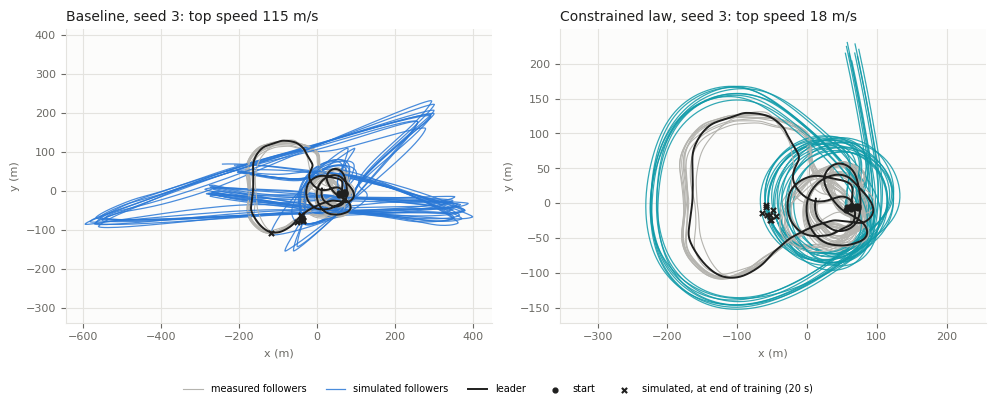

In [8]:
INK, MUTED, GRID, SURFACE = "#1f1f1e", "#6b6a65", "#e4e3df", "#fcfcfb"   # text and background colours
COLORS = {'full': "#2a78d6", 'hic': "#eb6834", 'aw2': "#eda100", 'pull_tail_v0': "#0f9aa8"}   # one per variant
plt.rcParams.update({'font.size': 8, 'savefig.facecolor': 'white', 'savefig.dpi': 200})


def quiet_axis(axis, title, log_scale=True):
    """Light grid, no top/right frame, neutral text colours (and a log y-axis unless log_scale=False)."""
    axis.set_title(title, loc="left", color=INK, fontsize=10)
    if log_scale:
        axis.set_yscale("log")
    axis.grid(True, color=GRID, linewidth=0.8)
    axis.set_facecolor(SURFACE)
    for side in ("top", "right"):
        axis.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        axis.spines[side].set_color(GRID)
    axis.tick_params(colors=MUTED, labelsize=8)


def plot_trajectories(sims, data, path):
    """Ground-frame flight paths of the showcase simulations next to the measured flight."""
    figure, axes = plt.subplots(1, len(sims), figsize=(10, 4))
    train_end = int(np.argmin(np.abs(data['t'] - TRAIN_END)))   # frame index of the end of training
    for axis, ((variant, seed), sim) in zip(axes, sims.items()):
        top_speed = runs[(runs.variant == variant) & (runs.seed == seed)].max_speed_sim.iloc[0]
        quiet_axis(axis, f"{LABELS[variant]}, seed {seed}: top speed {top_speed:.0f} m/s", log_scale=False)
        for i in range(1, data['X'].shape[1]):       # followers only (column 0 is the leader)
            axis.plot(data['X'][:, i], data['Y'][:, i], color="#b5b4af", linewidth=0.8,
                      label="measured followers" if i == 1 else None)   # label once for the legend
            axis.plot(sim['X'][:, i], sim['Y'][:, i], color=COLORS[variant], linewidth=0.9, alpha=0.85,
                      label="simulated followers" if i == 1 else None)
        axis.plot(data['X'][:, LEADER], data['Y'][:, LEADER], color=INK, linewidth=1.4, label="leader")
        axis.scatter(data['X'][0], data['Y'][0], s=12, color=INK, zorder=3, label="start")
        axis.scatter(sim['X'][train_end, 1:], sim['Y'][train_end, 1:], s=14, marker='x', color=INK, zorder=3,
                     label="simulated, at end of training (20 s)")
        axis.set_aspect('equal', adjustable='datalim')   # 1 m on x = 1 m on y
        axis.set_xlabel("x (m)", color=MUTED)
        axis.set_ylabel("y (m)", color=MUTED)
    figure.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=5, frameon=False, fontsize=7)
    figure.tight_layout(rect=(0, 0.07, 1, 1))            # leave room at the bottom for the legend
    figure.savefig(path)
    plt.show()


FIGURES_DIR.mkdir(exist_ok=True)
if len(showcase_sims) == len(SHOWCASE):
    plot_trajectories(showcase_sims, data, FIGURES_DIR / "trajectories.png")

## Metrics of every run

One dot per run; the bar is the median. Dashed lines: the
rigid formation (left) and the measured flock (centre, right).

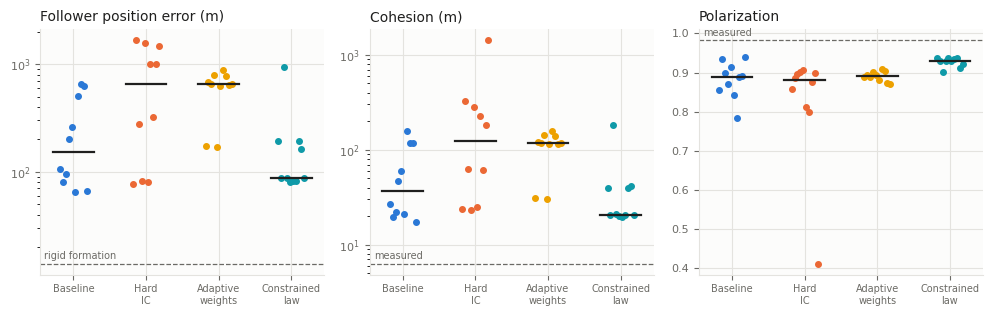

In [9]:
def plot_metrics(runs, path):
    """Dot plots of the 20-140 s error, cohesion and polarization for every run."""
    reference = runs.iloc[0]
    panels = [('pos_err_20_140s', 'Follower position error (m)', 'rigid_err_20_140s', 'rigid formation', True),
              ('cohesion_sim', 'Cohesion (m)', 'cohesion_data', 'measured', True),
              ('polar_sim', 'Polarization', 'polar_data', 'measured', False)]
    tick_labels = [LABELS[variant].replace(' ', '\n') for variant in VARIANTS_TO_SIMULATE]
    figure, axes = plt.subplots(1, 3, figsize=(10, 3.2))
    for axis, (column, title, ref_column, ref_label, log_scale) in zip(axes, panels):
        quiet_axis(axis, title, log_scale)
        for position, variant in enumerate(VARIANTS_TO_SIMULATE):
            group = runs[runs.variant == variant]
            values = group[column].to_numpy()
            jitter = np.linspace(-0.18, 0.18, len(values))         # spread the dots sideways
            axis.scatter(position + jitter, values, color=COLORS[variant], s=16, zorder=3)
            axis.plot([position - 0.28, position + 0.28], [np.median(values)] * 2, color=INK, linewidth=1.6, zorder=4)
        axis.axhline(reference[ref_column], color=MUTED, linestyle="--", linewidth=0.9)
        axis.annotate(ref_label, (0, reference[ref_column]), xycoords=("axes fraction", "data"),
                      xytext=(3, 3), textcoords="offset points", color=MUTED, fontsize=7)
        axis.set_xticks(range(len(VARIANTS_TO_SIMULATE)), tick_labels, color=MUTED, fontsize=7)
    figure.tight_layout()
    figure.savefig(path)
    plt.show()


plot_metrics(runs, FIGURES_DIR / "metrics.png")